# Preprocessing Technique 5: Feature Selection
IT25102054 - Dinali L. D. G. N.
**Group:** 26-MTR-IT2011-04
**Dataset:** Breast Cancer Wisconsin (Original) - UCI Machine Learning Repository

## 1. What is this technique?
**Feature selection** identifies which input variables are most useful for predicting the target and which are redundant or weakly informative. A common, interpretable approach for numeric data is **correlation analysis**: checking (a) how strongly each feature correlates with the target, and (b) how strongly features correlate with *each other* (multicollinearity), since two highly-correlated features carry largely duplicate information.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
 import os
 os.chdir('/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks')

In [3]:
 print(os.getcwd())
 os.listdir('../data/raw')

/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks


['Index', 'breast-cancer-wisconsin.names', 'breast-cancer-wisconsin.data']

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

COLS = ['Sample_code_number','Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
        'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei','Bland_Chromatin',
        'Normal_Nucleoli','Mitoses','Class']

RAW_PATH = '../data/raw/breast-cancer-wisconsin.data'
VIZ_DIR = '../results/eda_visualizations'
os.makedirs(VIZ_DIR, exist_ok=True)

df = pd.read_csv(RAW_PATH, names=COLS)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (699, 11)


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [5]:
df_f = df.copy()
df_f['Bare_Nuclei'] = df_f['Bare_Nuclei'].replace('?', np.nan).astype(float)
df_f['Bare_Nuclei'] = df_f['Bare_Nuclei'].fillna(df_f['Bare_Nuclei'].median())
feature_cols = ['Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
                'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei',
                'Bland_Chromatin','Normal_Nucleoli','Mitoses']
df_f[feature_cols] = df_f[feature_cols].astype(float)
df_f['Class_bin'] = df_f['Class'].map({2: 0, 4: 1})
df_f.head()

,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class,Class_bin
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,2,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,2,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,2,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,2,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,2,0


## 2. Why This Technique Was Needed
With only 9 features, this dataset is already small - feature selection here is less about *reducing* dimensionality for its own sake, and more about **understanding which features carry the strongest diagnostic signal**, and **flagging redundant (highly correlated) feature pairs** that could destabilise certain models (e.g. inflate coefficient variance in Logistic Regression) without adding real information.

In [6]:
corr_matrix = df_f[feature_cols + ['Class_bin']].corr(numeric_only=True)

target_corr = corr_matrix['Class_bin'].drop('Class_bin').sort_values(ascending=False)
print("Correlation of each feature with Class (malignant=1):")
print(target_corr.round(3))

Correlation of each feature with Class (malignant=1):
Bare_Nuclei                    0.819
Uniformity_of_Cell_Shape       0.819
Uniformity_of_Cell_Size        0.818
Bland_Chromatin                0.757
Clump_Thickness                0.716
Normal_Nucleoli                0.712
Marginal_Adhesion              0.697
Single_Epithelial_Cell_Size    0.683
Mitoses                        0.423
Name: Class_bin, dtype: float64


In [7]:
# Check for multicollinearity between predictive features themselves
feat_corr = corr_matrix.loc[feature_cols, feature_cols].copy()
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
                   .stack()
                   .sort_values(ascending=False))
print("Top 5 most correlated FEATURE PAIRS (potential redundancy):")
print(pairs.head(5).round(3))

Top 5 most correlated FEATURE PAIRS (potential redundancy):
Uniformity_of_Cell_Size   Uniformity_of_Cell_Shape       0.907
                          Bland_Chromatin                0.756
                          Single_Epithelial_Cell_Size    0.752
Uniformity_of_Cell_Shape  Bland_Chromatin                0.736
Uniformity_of_Cell_Size   Normal_Nucleoli                0.723
dtype: float64


**Findings:**
- **Strongest predictors of malignancy:** Bare_Nuclei **bold text** (r=0.82), **Uniformity_of_Cell_Shape** (r=0.82), and **Uniformity_of_Cell_Size** (r=0.82) - all three correlate very strongly with **Class**.
- **Weakest predictor:** **Mitoses** (r=0.42) - still positively correlated, but the least informative feature on its own.
- **Redundancy detected:** **Uniformity_of_Cell_Size** and **Uniformity_of_Cell_Shape** correlate at **r=0.91** with each other - the highest feature-to-feature correlation in the dataset. This makes sense biologically (an irregular cell size and an irregular cell shape tend to co-occur) but means the two columns carry substantially overlapping information.

## 3. Selection Decision
Given the dataset already has only 9 features (not hundreds), **we retain all 9 features for modelling** rather than dropping any outright - even **Mitoses**, the weakest, still correlates positively (r=0.42) and can contribute marginal signal in combination with others, especially for non-linear models like Decision Trees. However, we **flag **Uniformity_of_Cell_Size** / **Uniformity_of_Cell_Shape** as a redundant pair** worth monitoring for multicollinearity if we use Logistic Regression, and this correlation insight directly motivates the **dimensionality reduction (PCA)** step performed by our teammate next.

## 4. EDA Visualization & Interpretation

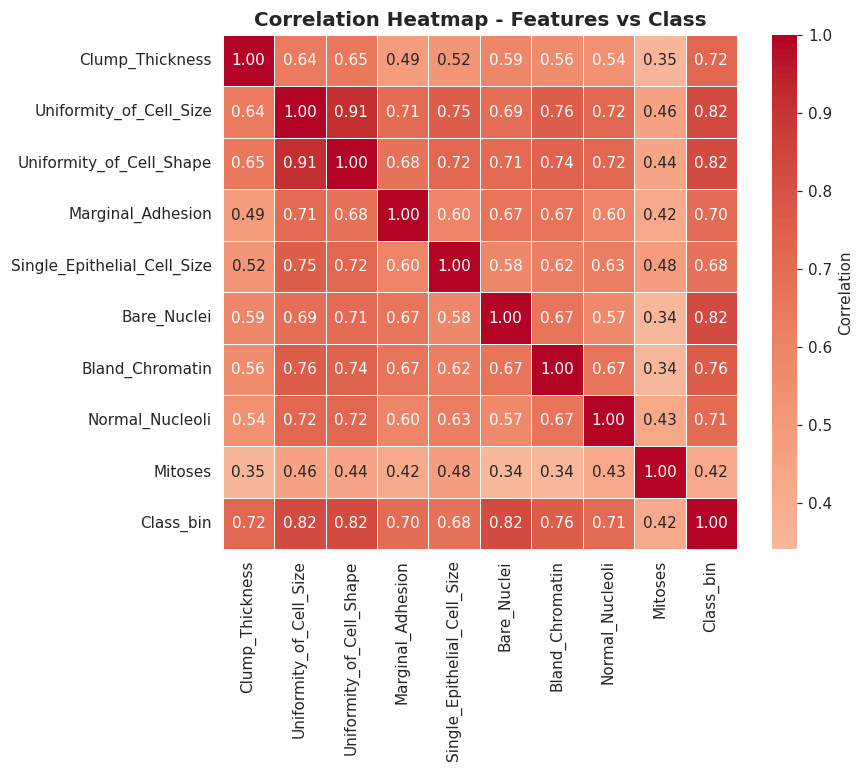

In [9]:
plt.figure(figsize=(8.5, 7))
sns.heatmap(corr_matrix.round(2), annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'label': 'Correlation'}, fmt='.2f')
plt.title('Correlation Heatmap - Features vs Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/05_feature_correlation_heatmap.png', bbox_inches='tight')
plt.show()

**Interpretation:** The heatmap's bottom row/rightmost column shows correlation with **Class_bin** - every feature is a **medium-to-strong positive predictor** (all above 0.4), which is a strong quality signal for this dataset (justifying our earlier "Dataset Justification" slide). The darkest red cell off the diagonal (**Uniformity_of_Cell_Size** × **Uniformity_of_Cell_Shape**, 0.91) visually confirms the redundant-pair finding above.

## 5. Summary
| Item | Result |
|---|---|
| Technique | Correlation-based feature selection |
| Strongest predictors | Bare_Nuclei, Uniformity_of_Cell_Shape, Uniformity_of_Cell_Size (r≈0.82) |
| Weakest predictor | Mitoses (r=0.42) - still retained |
| Redundant pair found | Uniformity_of_Cell_Size ↔ Uniformity_of_Cell_Shape (r=0.91) |
| Features dropped | None - all 9 retained (small feature set, all positively correlated) |
| Follow-up action | Redundancy motivates PCA-based dimensionality reduction (next notebook) |